In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

dataset_path = (
    project_root
    / "data"
    / "raw"
    / "manufacturing_6G_dataset.csv"
)

figures_dir = project_root / "figures"
figures_dir.mkdir(exist_ok=True)

df = pd.read_csv(dataset_path)

df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print("Dataset shape:", df.shape)
print("Dataset loaded successfully.")

Dataset shape: (100000, 13)
Dataset loaded successfully.


In [2]:
# Define feature groups
numerical_features = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Production_Speed_units_per_hr",
    "Predictive_Maintenance_Score",
    "Error_Rate_%"
]

categorical_features = [
    "Operation_Mode"
]

target = "Efficiency_Status"

class_order = [
    "Low",
    "Medium",
    "High"
]

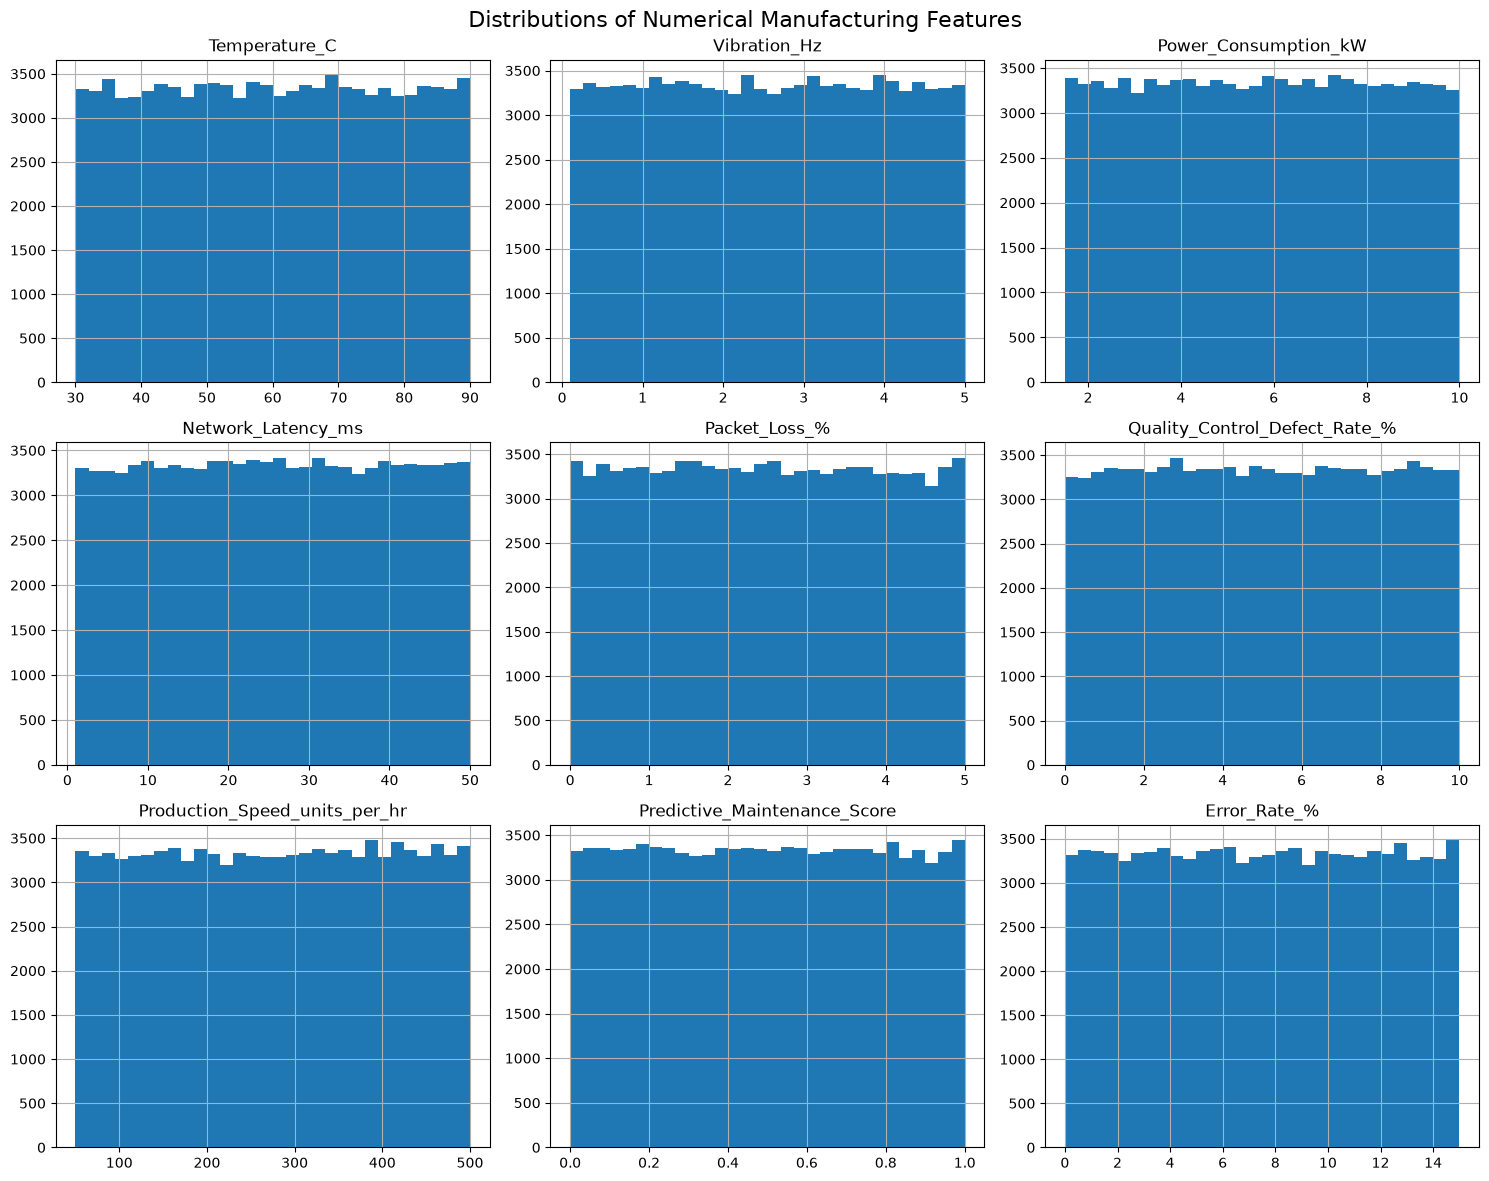

In [4]:
# Plot distributions of all numerical features
df[numerical_features].hist(
    bins=30,
    figsize=(15, 12)
)

plt.suptitle(
    "Distributions of Numerical Manufacturing Features",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    figures_dir / "numerical_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
# Calculate skewness
skewness = (
    df[numerical_features]
    .skew()
    .sort_values(ascending=False)
)

print(skewness)

Packet_Loss_%                    0.008407
Predictive_Maintenance_Score     0.002895
Error_Rate_%                     0.000929
Quality_Control_Defect_Rate_%    0.000495
Vibration_Hz                    -0.000017
Network_Latency_ms              -0.000874
Power_Consumption_kW            -0.000885
Temperature_C                   -0.000946
Production_Speed_units_per_hr   -0.010182
dtype: float64


#### all the values are near to zero, means basically there are no theoritical skewness on any numerical feature

/var/folders/yn/3b1_rbb17l35dzjtgnqxyvq80000gn/T/ipykernel_89028/3260762273.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


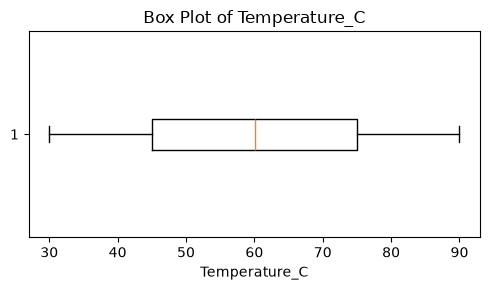

/var/folders/yn/3b1_rbb17l35dzjtgnqxyvq80000gn/T/ipykernel_89028/3260762273.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


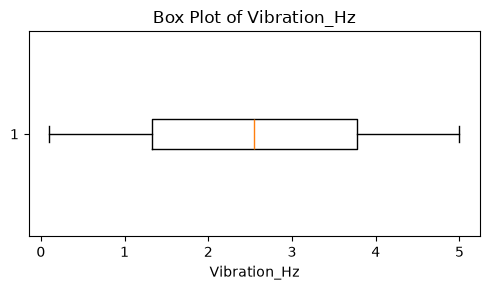

/var/folders/yn/3b1_rbb17l35dzjtgnqxyvq80000gn/T/ipykernel_89028/3260762273.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


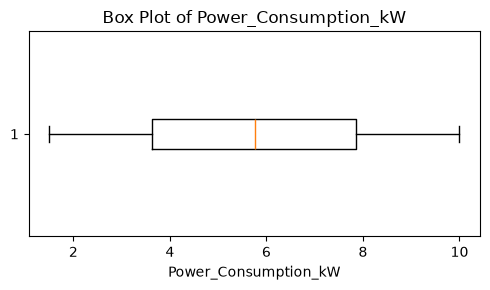

/var/folders/yn/3b1_rbb17l35dzjtgnqxyvq80000gn/T/ipykernel_89028/3260762273.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


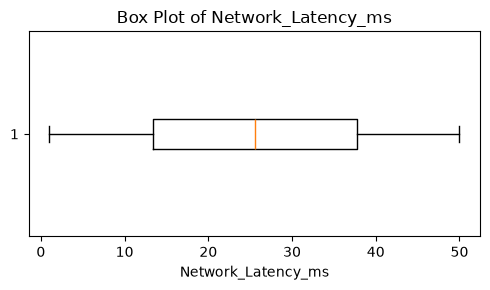

/var/folders/yn/3b1_rbb17l35dzjtgnqxyvq80000gn/T/ipykernel_89028/3260762273.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


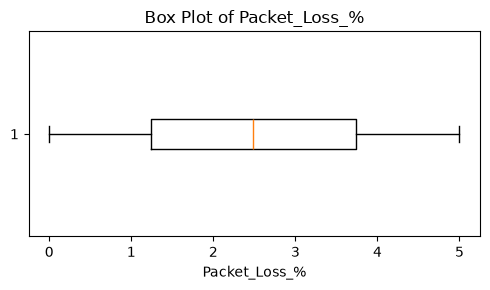

/var/folders/yn/3b1_rbb17l35dzjtgnqxyvq80000gn/T/ipykernel_89028/3260762273.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


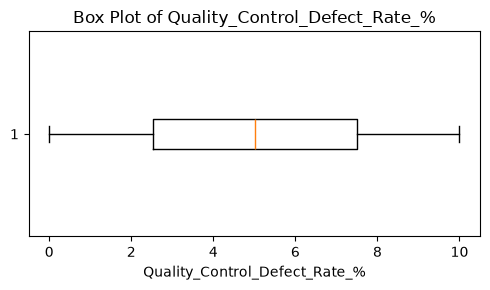

/var/folders/yn/3b1_rbb17l35dzjtgnqxyvq80000gn/T/ipykernel_89028/3260762273.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


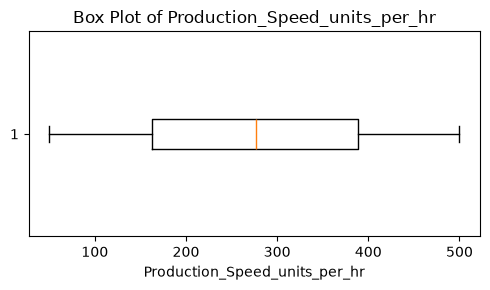

/var/folders/yn/3b1_rbb17l35dzjtgnqxyvq80000gn/T/ipykernel_89028/3260762273.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


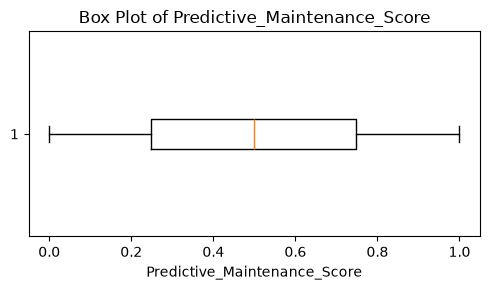

/var/folders/yn/3b1_rbb17l35dzjtgnqxyvq80000gn/T/ipykernel_89028/3260762273.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


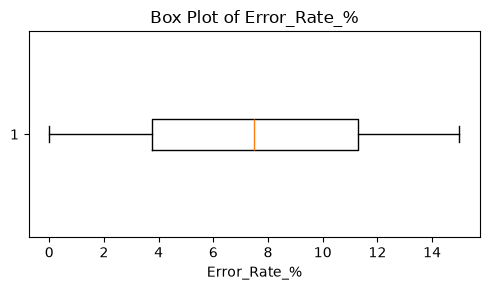

In [ ]:
# Box plots for numerical features
# Because the features use completely different scales, create one plot per feature.
# Histograms show the overall shape.
# Box plots make it easier to detect extreme observations.

for feature in numerical_features:

    plt.figure(figsize=(5, 3))

    plt.boxplot(
        df[feature],
        vert=False
    )

    plt.title(f"Box Plot of {feature}")
    plt.xlabel(feature)

    plt.tight_layout()
    plt.show()

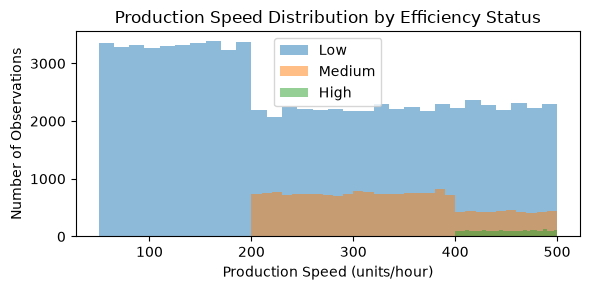

In [12]:
# Compare Production Speed distributions across efficiency classes
plt.figure(figsize=(6, 3))

for efficiency_class in class_order:

    values = df[
        df["Efficiency_Status"] == efficiency_class
    ]["Production_Speed_units_per_hr"]

    plt.hist(
        values,
        bins=30,
        alpha=0.5,
        label=efficiency_class
    )

plt.title(
    "Production Speed Distribution by Efficiency Status"
)

plt.xlabel(
    "Production Speed (units/hour)"
)

plt.ylabel(
    "Number of Observations"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "production_speed_by_efficiency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

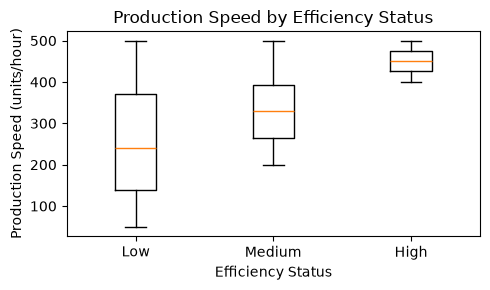

In [13]:
# Production Speed box plot by class
production_data = [
    df[
        df["Efficiency_Status"] == efficiency_class
    ]["Production_Speed_units_per_hr"]
    for efficiency_class in class_order
]

plt.figure(figsize=(5, 3))

plt.boxplot(
    production_data,
    tick_labels=class_order
)

plt.title(
    "Production Speed by Efficiency Status"
)

plt.xlabel(
    "Efficiency Status"
)

plt.ylabel(
    "Production Speed (units/hour)"
)

plt.tight_layout()

plt.show()

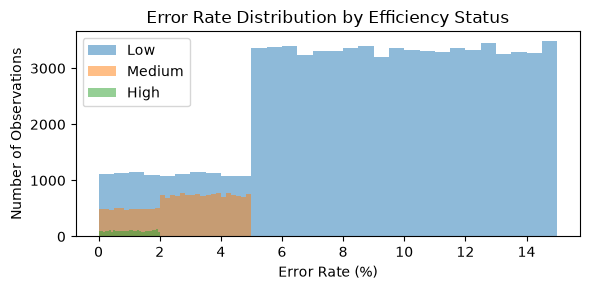

In [15]:
# Error Rate distributions across classes
plt.figure(figsize=(6, 3))

for efficiency_class in class_order:

    values = df[
        df["Efficiency_Status"] == efficiency_class
    ]["Error_Rate_%"]

    plt.hist(
        values,
        bins=30,
        alpha=0.5,
        label=efficiency_class
    )

plt.title(
    "Error Rate Distribution by Efficiency Status"
)

plt.xlabel(
    "Error Rate (%)"
)

plt.ylabel(
    "Number of Observations"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "error_rate_by_efficiency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

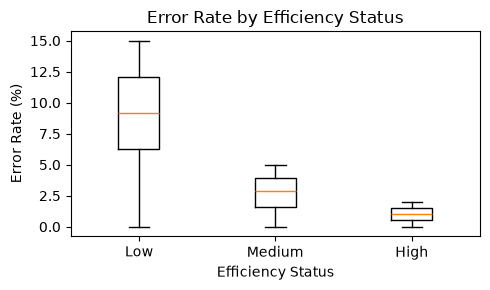

In [17]:
# Error Rate box plot by class
error_data = [
    df[
        df["Efficiency_Status"] == efficiency_class
    ]["Error_Rate_%"]
    for efficiency_class in class_order
]

plt.figure(figsize=(5, 3))

plt.boxplot(
    error_data,
    tick_labels=class_order
)

plt.title(
    "Error Rate by Efficiency Status"
)

plt.xlabel(
    "Efficiency Status"
)

plt.ylabel(
    "Error Rate (%)"
)

plt.tight_layout()

plt.show()

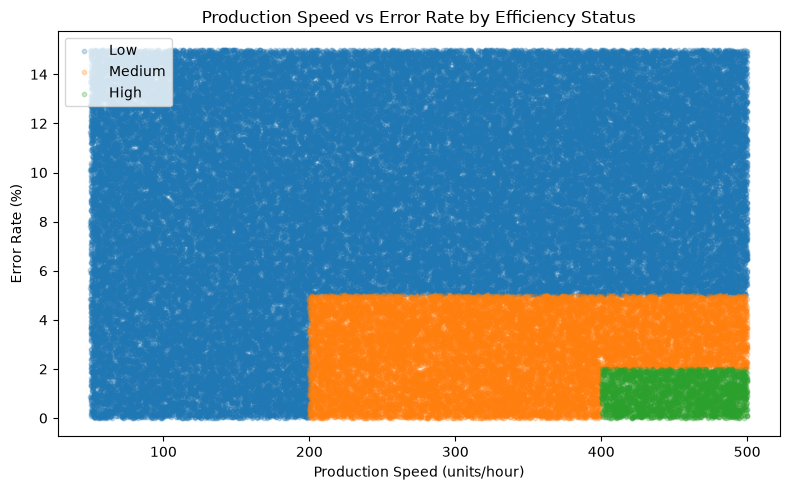

In [22]:
# Scatter plot of Production Speed against Error Rate
plt.figure(figsize=(8, 5))

for efficiency_class in class_order:

    subset = df[
        df["Efficiency_Status"] == efficiency_class
    ]

    plt.scatter(
        subset["Production_Speed_units_per_hr"],
        subset["Error_Rate_%"],
        alpha=0.25,
        s=10,
        label=efficiency_class
    )

plt.title(
    "Production Speed vs Error Rate by Efficiency Status"
)

plt.xlabel(
    "Production Speed (units/hour)"
)

plt.ylabel(
    "Error Rate (%)"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "production_speed_vs_error_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Compare other numerical features across classes

other_features = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Predictive_Maintenance_Score"
]

other_class_means = (
    df.groupby("Efficiency_Status")[
        other_features
    ]
    .mean()
    .reindex(class_order)
    .round(3)
)

other_class_means

,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Predictive_Maintenance_Score
Efficiency_Status,,,,,,,
Low,60.006,2.550,5.743,25.562,2.494,5.017,0.500
Medium,60.154,2.552,5.762,25.566,2.487,4.989,0.498
High,60.232,2.548,5.718,25.334,2.528,4.930,0.495


In [ ]:
# Standardize class means for visual comparison
feature_means = (
    df.groupby("Efficiency_Status")[
        numerical_features
    ]
    .mean()
    .reindex(class_order)
)

# found this on stackoverflow
# How many standard deviations => above or below the overall mean?
standardized_means = (feature_means - df[numerical_features].mean()) / df[numerical_features].std()

standardized_means

,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%
Efficiency_Status,,,,,,,,,
Low,-0.002024,-0.000224,-0.001194,0.000417,0.000257,0.002727,-0.161894,0.001537,0.328828
Medium,0.006496,0.001098,0.006595,0.000756,-0.004731,-0.006830,0.447426,-0.003764,-1.100457
High,0.011015,-0.001208,-0.011257,-0.015713,0.023711,-0.027190,1.344191,-0.015861,-1.498444


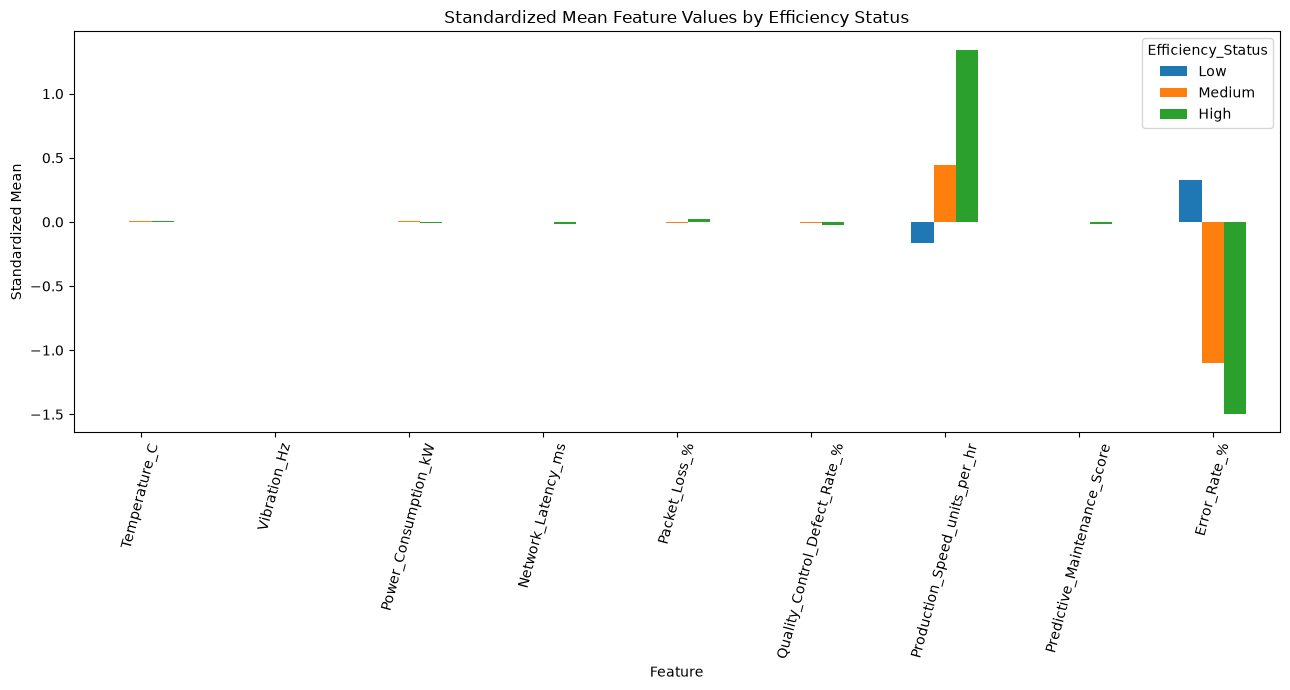

In [28]:
# Visualize standardized class means
standardized_means.T.plot(
    kind="bar",
    figsize=(13, 7)
)

plt.title(
    "Standardized Mean Feature Values by Efficiency Status"
)

plt.xlabel(
    "Feature"
)

plt.ylabel(
    "Standardized Mean"
)

plt.xticks(
    rotation=75
)

plt.tight_layout()

plt.show()

In [ ]:
# Operation Mode distribution (investigating the categorical feature)
# Operation_Mode is categorical.
# Therefore we do not calculate a normal Pearson correlation with it.
# Instead, a contingency table tells us how efficiency classes are distributed across operation modes.
operation_counts = pd.crosstab(
    df["Operation_Mode"],
    df["Efficiency_Status"]
)

operation_counts

Efficiency_Status,High,Low,Medium
Operation_Mode,,,
Active,2124,54434,13496
Idle,570,15695,3792
Maintenance,292,7696,1901


In [ ]:
# Operation Mode percentages
# in here we are normalizing the operation mode percentages because Comparing raw counts directly is unfair.
operation_percentages = (
    pd.crosstab(
        df["Operation_Mode"],
        df["Efficiency_Status"],
        normalize="index"
    )
    * 100
)

operation_percentages.round(2)

Efficiency_Status,High,Low,Medium
Operation_Mode,,,
Active,3.03,77.70,19.27
Idle,2.84,78.25,18.91
Maintenance,2.95,77.82,19.22


In [31]:
# Investigate Machine ID against target
# Even though we plan to exclude Machine ID, 
# it is useful to verify whether particular machines have very different target distributions.

machine_efficiency = (
    pd.crosstab(
        df["Machine_ID"],
        df["Efficiency_Status"],
        normalize="index"
    )
    * 100
)

machine_efficiency.head(10)

Efficiency_Status,High,Low,Medium
Machine_ID,,,
1,2.870564,76.878914,20.250522
2,2.841744,78.196962,18.961293
3,2.798601,78.660670,18.540730
4,2.544910,78.243513,19.211577
5,3.671072,77.777778,18.551150
6,2.998966,77.197518,19.803516
7,3.155216,77.506361,19.338422
8,2.745297,80.427046,16.827656
9,2.712205,79.457559,17.830236


#### We initially excluded Machine ID because it is an identifier.
but are some machines consistently more efficient than others?
* If all machines have similar class distributions, excluding Machine ID becomes even easier to justify.

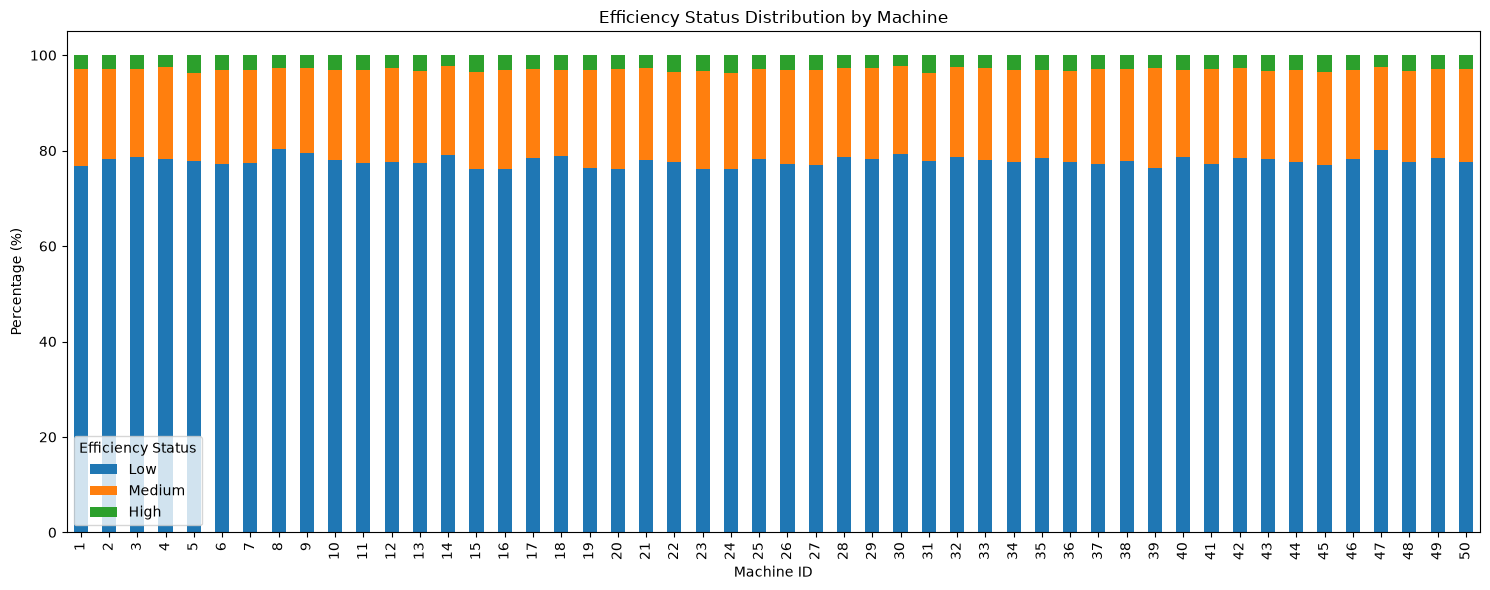

In [32]:
# Visualize efficiency by machine
machine_efficiency[
    class_order
].plot(
    kind="bar",
    stacked=True,
    figsize=(15, 6)
)

plt.title(
    "Efficiency Status Distribution by Machine"
)

plt.xlabel(
    "Machine ID"
)

plt.ylabel(
    "Percentage (%)"
)

plt.legend(
    title="Efficiency Status"
)

plt.tight_layout()

plt.show()

In [ ]:
# Create time based exploratory features
# Raw timestamp is usually not meaningful directly to an ML algorithm.

df["Hour"] = df["Timestamp"].dt.hour

df["Day_Of_Week"] = (
    df["Timestamp"]
    .dt.day_name()
)

df[
    [
        "Timestamp",
        "Hour",
        "Day_Of_Week"
    ]
].head()

,Timestamp,Hour,Day_Of_Week
0,2024-01-01 00:00:00,0,Monday
1,2024-01-01 00:01:00,0,Monday
2,2024-01-01 00:02:00,0,Monday
3,2024-01-01 00:03:00,0,Monday
4,2024-01-01 00:04:00,0,Monday


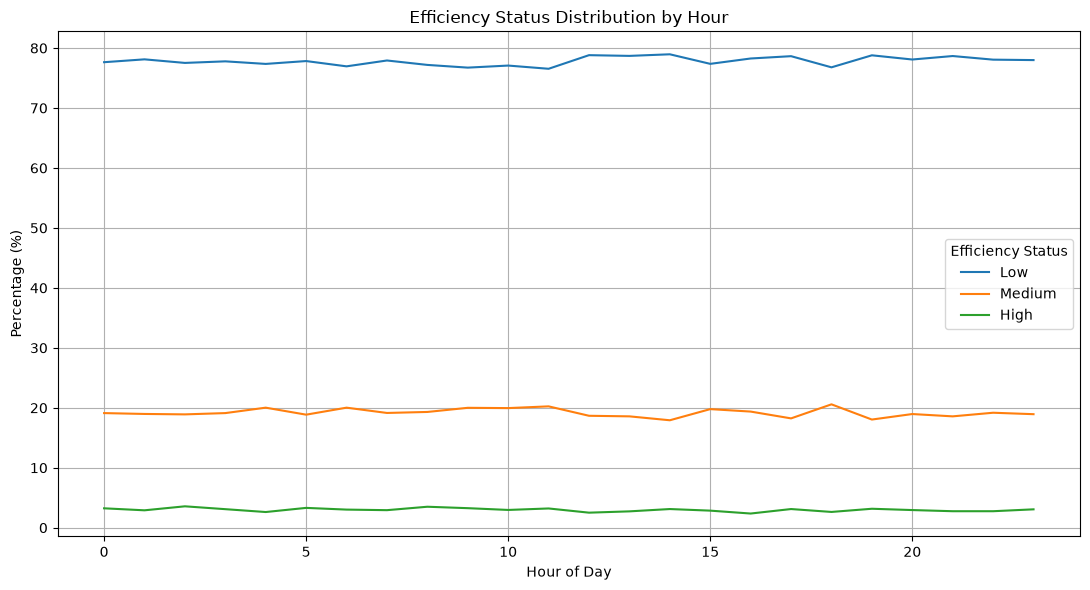

In [35]:
# Check efficiency distribution by hour
hour_efficiency = (
    pd.crosstab(
        df["Hour"],
        df["Efficiency_Status"],
        normalize="index"
    )
    * 100
)

hour_efficiency.round(2)

hour_efficiency[
    class_order
].plot(
    figsize=(11, 6)
)

plt.title(
    "Efficiency Status Distribution by Hour"
)

plt.xlabel(
    "Hour of Day"
)

plt.ylabel(
    "Percentage (%)"
)

plt.legend(
    title="Efficiency Status"
)

plt.grid()

plt.tight_layout()

plt.show()

##### If the percentages remain nearly constant, there may be little reason to add Hour to the model.

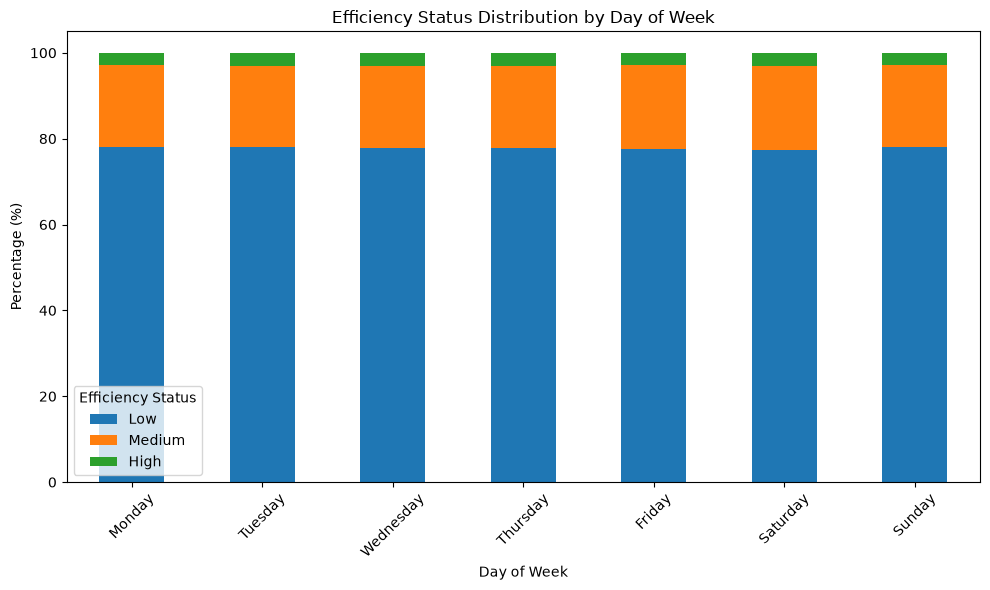

In [37]:
# Day of week analysis
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_efficiency = (
    pd.crosstab(
        df["Day_Of_Week"],
        df["Efficiency_Status"],
        normalize="index"
    )
    * 100
)

day_efficiency = day_efficiency.reindex(
    day_order
)

day_efficiency.round(2)

day_efficiency[
    class_order
].plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title(
    "Efficiency Status Distribution by Day of Week"
)

plt.xlabel(
    "Day of Week"
)

plt.ylabel(
    "Percentage (%)"
)

plt.xticks(
    rotation=45
)

plt.legend(
    title="Efficiency Status"
)

plt.tight_layout()

plt.show()

#### We have investigated temporal feature engineering but do not currently have strong evidence that time based features improve the prediction problem.

In [38]:
# Remove temporary EDA features
df.drop(
    columns=[
        "Hour",
        "Day_Of_Week"
    ],
    inplace=True
)

print(df.shape)

(100000, 13)


In [39]:
# summary statistics
eda_summary = (
    df.groupby("Efficiency_Status")[
        [
            "Production_Speed_units_per_hr",
            "Error_Rate_%",
            "Temperature_C",
            "Vibration_Hz",
            "Power_Consumption_kW"
        ]
    ]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)

eda_summary

Production_Speed_units_per_hr                             \
                                           mean      std      min      max   
Efficiency_Status                                                            
High                                    450.791   28.830  400.122  499.981   
Low                                     254.854  132.739   50.000  499.997   
Medium                                  334.125   81.657  200.007  499.977   

                  Error_Rate_%                   Temperature_C          \
                          mean    std  min   max          mean     std   
Efficiency_Status                                                        
High                     1.007  0.577  0.0   2.0        60.232  17.445   
Low                      8.930  3.794  0.0  15.0        60.006  17.318   
Medium                   2.733  1.398  0.0   5.0        60.154  17.325   

                                  Vibration_Hz                       \
                      min     max         mean    std    min    max   
Efficiency_Status                                                     
High               30.013  89.999        2.548  1.407  0.101  4.999   
Low                30.000  89.999        2.550  1.414  0.100  5.000   
Medium             30.000  89.993        2.552  1.415  0.100  5.000   

                  Power_Consumption_kW                        
                                  mean    std    min     max  
Efficiency_Status                                             
High                             5.718  2.453  1.503   9.998  
Low                              5.743  2.451  1.500  10.000  
Medium                           5.762  2.454  1.500   9.999

# Exploratory Data Analysis Conclusions

## Numerical Feature Distributions

The numerical manufacturing variables were analysed using histograms, descriptive statistics, skewness measurements, and box plots.

The analysis was used to investigate:

* distribution shapes
* different numerical scales
* potential extreme observations
* variability within each feature

Potential outliers were identified using the Interquartile Range method. However, observations were not automatically removed because unusual industrial measurements may represent genuine machine conditions rather than incorrect data.

## Efficiency Class Analysis

The distributions of numerical features were compared across the three target classes:

`Low`

`Medium`

`High`

Production Speed and Error Rate showed the clearest separation between the efficiency classes.

### Production Speed

Higher efficiency classes generally showed substantially higher Production Speed.

The approximate class means were:

`Low` ≈ 254.9 units/hour

`Medium` ≈ 334.1 units/hour

`High` ≈ 450.8 units/hour

### Error Rate

Higher efficiency classes showed substantially lower Error Rates.

The approximate class means were:

`Low` ≈ 8.93%

`Medium` ≈ 2.73%

`High` ≈ 1.01%

The full distributions and box plots confirmed that these differences were not only caused by differences in the mean values.

## Production Speed and Error Rate Relationship

A scatter plot of Production Speed against Error Rate showed clear regions corresponding to the Low, Medium, and High efficiency classes.

The observed class boundaries were consistent with the threshold relationship identified during Day 1:

```text
Production Speed >= 400
and Error Rate <= 2
    High

Production Speed >= 200
and Error Rate <= 5
    Medium

Otherwise
    Low
```

This provides strong evidence that these two features contain most of the information required to reproduce the provided `Efficiency_Status` labels.

This relationship should not be interpreted as proof that Production Speed and Error Rate cause manufacturing efficiency. It demonstrates how the target labels are structured within this dataset.

## Other Numerical Features

Features such as Temperature, Vibration, Power Consumption, Network Latency, Packet Loss, Quality Control Defect Rate, and Predictive Maintenance Score showed much weaker visible separation between the efficiency classes.

These features will not be removed at this stage.

Their usefulness will be evaluated during model training and later feature importance experiments.

## Operation Mode

The relationship between `Operation_Mode` and `Efficiency_Status` was analysed using normalized contingency tables.

This allowed the class proportions to be compared fairly between Active, Idle, and Maintenance states.

The results will be considered when determining whether Operation Mode provides useful predictive information.

## Machine ID

Efficiency distributions were also compared across the 50 machines.

`Machine_ID` remains an identifier rather than a physical numerical measurement.

It will therefore initially be excluded from the model input unless later analysis provides a strong reason to include machine specific information.

## Temporal Analysis

The Timestamp column was temporarily transformed into:

`Hour`

`Day_Of_Week`

These features were used only for exploratory analysis.

The purpose was to investigate whether manufacturing efficiency showed meaningful time based patterns.

Time based features will only be included in later modelling if the exploratory analysis provides evidence that they contain useful predictive information.

## Conclusion

The exploratory analysis confirms that Production Speed and Error Rate provide very strong separation between the three efficiency classes.

Most other features show substantially weaker visible relationships with the target.

The next stage of the project will prepare the dataset for machine learning by:

* defining the final input features and target
* creating stratified training and test sets
* encoding categorical variables
* scaling numerical features where required
* building preprocessing pipelines
* training the first baseline classification models